# What is associated with GitHub repository stars?

An analysis of **483k public repositories with at least 100 stars** (GitHub search snapshot, collected 2026-10-10).

**Question.** Among repositories that already have ≥100 stars, which public metadata are associated with a repository's star count, and how well can a model recover `log(stars)` for repositories it has never seen?

**What this notebook does and does not claim**
- It measures **current associations** inside a selected sample (≥100 stars). It does **not** show that any feature *causes* stars, and it does **not** predict success at repository creation.
- The strongest predictors, forks and open issues, are measured in the **same snapshot** as stars (all three are consequences of attention). They are therefore analysed as a *cross-sectional association* task (Task A). A **profile-only** task without them (Task B) is reported separately.

**Evaluation protocol (no test-set peeking)**
1. 60 / 20 / 20 train / validation / test split, **grouped by owner** (an owner's repositories never straddle splits).
2. Top-language / top-license groups and the forks centring constant are learned **from the training rows only**.
3. Polynomial degree and gradient-boosting hyper-parameters are chosen on the **validation** set.
4. Chosen models are refit on train + validation and scored **once** on the untouched test set, with owner-clustered bootstrap intervals.
5. A **time-based holdout** (train on repositories created ≤ 2022, test on ≥ 2023) checks whether the findings carry over to newer cohorts. It repeats steps 1–4 *inside the pre-2023 data only*: polynomial degree and boosting parameters are chosen on a validation split of the pre-2023 rows, the models are refit on all pre-2023 rows, and the 2023+ cohort is scored once. No 2023+ row influences any choice.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path('src').resolve()))
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from stars_lib import *

FIG, RES = Path('figures'), Path('results')
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
results = {}            # everything quoted in the README is written to results/metrics.json

INDIGO, EMERALD, AMBER, ROSE, SLATE = '#4f46e5', '#10b981', '#f59e0b', '#e11d48', '#64748b'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.edgecolor': '#334155',
    'axes.prop_cycle': plt.cycler(color=[INDIGO, EMERALD, AMBER, ROSE, SLATE])})

def save(fig, name):
    fig.savefig(FIG / name); plt.show()

## 1. Data and cleaning

In [2]:
raw, source = load_data()
source_sha256 = sha256_file(FULL_CSV if source == FULL_CSV.name else SAMPLE_CSV)
print('source file:', source, '| sha256:', source_sha256[:16] + '…', '| raw rows:', len(raw))
print('duplicate repo_ids:', raw.repo_id.duplicated().sum(), '| rows with stars < 100:', (raw.stars < MIN_STARS).sum())
df = add_features(clean(raw))
print('rows used:', len(df), '| owners:', df.owner.nunique(), '| missing values:', int(df.isna().sum().sum()))
print('created', df.created_year.min(), '-', df.created_year.max(), '| collected on', raw.collected_on.iloc[0])
results['data'] = {'source_file': source, 'source_sha256': source_sha256, 'raw_rows': len(raw), 'rows_used': len(df), 'owners': int(df.owner.nunique()),
                   'collected_on': str(raw.collected_on.iloc[0])}
df[['stars', 'forks', 'open_issues', 'age_years', 'language', 'license']].describe(include='all').T

source file: github_repos_all.csv | sha256: b842bc9d48a3c533… | raw rows: 483349
duplicate repo_ids: 0 | rows with stars < 100: 1


rows used: 483348 | owners: 257344 | missing values: 0
created 2007 - 2026 | collected on 2026-10-10


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
stars,483348.0,NaN,NaN,NaN,874.073701,4445.282504,100.0,143.0,232.0,515.0,552370.0
forks,483348.0,NaN,NaN,NaN,162.839255,1058.587079,0.0,21.0,45.0,104.0,241653.0
open_issues,483348.0,NaN,NaN,NaN,28.737876,272.085668,0.0,1.0,6.0,19.0,121649.0
age_years,483348.0,NaN,NaN,NaN,7.372422,4.147193,0.0,4.052055,7.383562,10.441096,18.958904
language,483348,493,Python,95989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
license,483348,49,MIT,173169,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Exploratory look

Stars are extremely right-skewed, so the response is `log(stars)`. Because the sample is truncated at 100 stars, `log(stars)` starts at 4.6 and the distribution is still right-skewed.

skewness of stars: 38.0 | of log(stars): 1.51
correlation log(stars) ~ log(1 + forks): 0.72


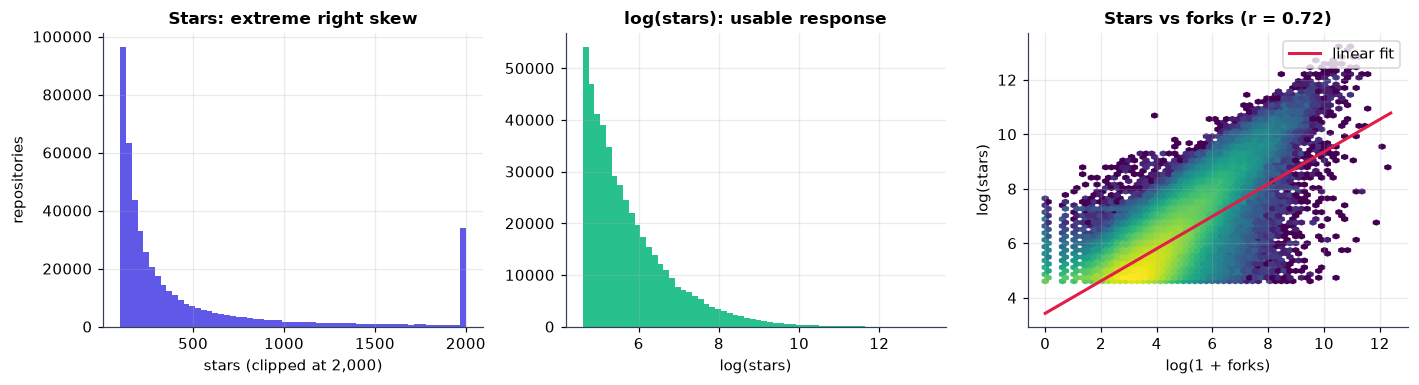

In [3]:
print('skewness of stars: %.1f | of log(stars): %.2f' % (df.stars.skew(), df.log_stars.skew()))
print('correlation log(stars) ~ log(1 + forks): %.2f' % df.log_stars.corr(df.log_forks))
results['eda'] = {'skew_stars': df.stars.skew(), 'skew_log_stars': df.log_stars.skew(),
                  'corr_logstars_logforks': df.log_stars.corr(df.log_forks)}

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(df.stars.clip(upper=2000), bins=60, color=INDIGO, alpha=.9)
ax[0].set(xlabel='stars (clipped at 2,000)', ylabel='repositories', title='Stars: extreme right skew')
ax[1].hist(df.log_stars, bins=60, color=EMERALD, alpha=.9)
ax[1].set(xlabel='log(stars)', title='log(stars): usable response')
hb = ax[2].hexbin(df.log_forks, df.log_stars, gridsize=60, bins='log', cmap='viridis', mincnt=1)
b = np.polyfit(df.log_forks, df.log_stars, 1); xs = np.linspace(0, df.log_forks.max(), 50)
ax[2].plot(xs, b[0] * xs + b[1], color=ROSE, lw=2, label='linear fit')
ax[2].set(xlabel='log(1 + forks)', ylabel='log(stars)', title='Stars vs forks (r = %.2f)' % results['eda']['corr_logstars_logforks']); ax[2].legend()
fig.tight_layout(); save(fig, '01_distributions.png')

## 3. Splits

Owner-grouped random split for model selection and testing; a separate time-based split is used later as a robustness check.

In [4]:
train, val, test = three_way_split(df)
for name, part in [('train', train), ('validation', val), ('test', test)]:
    print(f'{name:10s} {len(part):7d} repos, {part.owner.nunique():6d} owners')
assert not (set(train.owner) & set(val.owner)) and not (set(train.owner) & set(test.owner)) and not (set(val.owner) & set(test.owner))
print('owner overlap between splits: none')
results['split'] = {'train': len(train), 'validation': len(val), 'test': len(test), 'seed': SEED}

dev = pd.concat([train, val])            # used only for the final refit

train       291100 repos, 154406 owners
validation   97017 repos,  51469 owners
test         95231 repos,  51469 owners


owner overlap between splits: none


## 4. Model selection on the validation set

Candidates (all predict `log(stars)`):
- **M0** simple regression on `log(1 + forks)`
- **M1** multiple regression on 19 numeric/binary features (incl. `has_license`)
- **M2** M1 + language and license dummies (top-12 languages / top-6 licenses from the *training* rows)
- **M3** M2 with a polynomial of degree *d* in centred `log(1 + forks)`; *d* chosen below
- **GB** gradient boosting (histogram-based) with learning rate and leaf count chosen below

In [5]:
best_d, deg = select_degree(train, val)      # smallest degree within 0.002 RMSE of the best validation RMSE
print('chosen polynomial degree:', best_d, '(validation RMSE-optimal degree: %d)' % deg.loc[deg.RMSE_val.idxmin(), 'degree'])
results['selection_degree'] = {'chosen': best_d, 'table': deg.round(4).to_dict('records')}
deg.round(4)

chosen polynomial degree: 3 (validation RMSE-optimal degree: 6)


,degree,R2_train,R2_val,RMSE_val
0,1,0.5845,0.6029,0.6716
1,2,0.6351,0.6512,0.6294
2,3,0.6417,0.6565,0.6246
3,4,0.6431,0.6579,0.6233
4,5,0.6435,0.6583,0.6229
5,6,0.6435,0.6583,0.6229


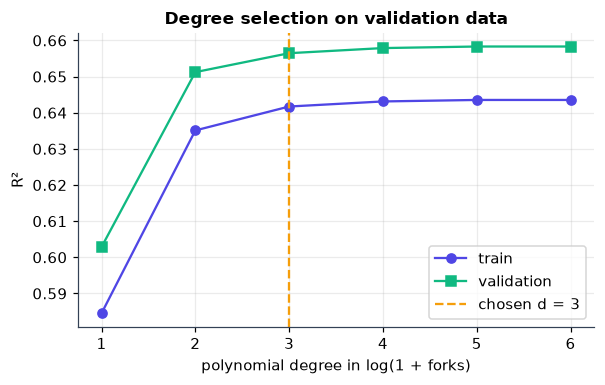

In [6]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.plot(deg.degree, deg.R2_train, 'o-', color=INDIGO, label='train')
ax.plot(deg.degree, deg.R2_val, 's-', color=EMERALD, label='validation')
ax.axvline(best_d, color=AMBER, ls='--', label=f'chosen d = {best_d}')
ax.set(xlabel='polynomial degree in log(1 + forks)', ylabel='R²', title='Degree selection on validation data'); ax.legend()
fig.tight_layout(); save(fig, '02_degree_selection.png')

In [7]:
best_gb, gb_grid = select_gb(train, val)
print('chosen gradient-boosting parameters:', best_gb)
results['selection_gb'] = {'chosen': best_gb, 'table': gb_grid.round(4).to_dict('records')}
gb_grid.round(4)

chosen gradient-boosting parameters: {'learning_rate': 0.1, 'max_leaf_nodes': 31}


,learning_rate,max_leaf_nodes,R2_val,RMSE_val,n_iter
0,0.05,31,0.7006,0.5831,500
1,0.05,127,0.7026,0.5812,347
2,0.10,31,0.7029,0.5808,500
3,0.10,127,0.7016,0.5821,173


## 5. Final evaluation on the untouched test set

Task A (association): models use forks and open issues. Task B (profile-only): the same model families **without** forks and issues. Every model is refit on train + validation (learning the language/license groups from those rows) and scored once on test. The 95 % intervals resample *owners*, not rows.

In [8]:
SPECS = make_specs(best_d, best_gb)
final, test_pred, rows = {}, {}, []
for name, spec in SPECS.items():
    final[name] = FittedModel(spec, dev)
    test_pred[name] = final[name].predict(test)
    s = scores(test.log_stars, test_pred[name])
    lo, hi = cluster_bootstrap_r2(test.log_stars, test_pred[name], test.owner)
    rows.append({'model': name, **s, 'R2_lo': lo, 'R2_hi': hi})
final_table = pd.DataFrame(rows)
results['test'] = final_table.round(4).to_dict('records')
final_table.round(3)

,model,R2,RMSE,MAE,within_2x,R2_lo,R2_hi
0,A M0 forks only,0.515,0.732,0.572,0.679,0.498,0.530
1,A M1 multiple regression,0.579,0.682,0.530,0.715,0.565,0.592
2,"A M2 + language, license",0.587,0.675,0.525,0.720,0.574,0.600
3,A M3 M2 + degree-3 forks,0.637,0.633,0.481,0.765,0.620,0.652
4,A GB gradient boosting,0.689,0.586,0.444,0.803,0.677,0.701
5,B M2 profile-only OLS,0.138,0.976,0.747,0.560,0.130,0.145
6,B GB profile-only boosting,0.183,0.951,0.726,0.581,0.175,0.191


In [9]:
for tag in ('A  GB  gradient boosting', 'B  GB  profile-only boosting'):
    r = final_table.set_index('model').loc[tag]
    print('%s: typical error exp(MAE) = x%.2f | within a factor of 2: %.1f%%' % (tag, np.exp(r.MAE), 100 * r.within_2x))

A  GB  gradient boosting: typical error exp(MAE) = x1.56 | within a factor of 2: 80.3%
B  GB  profile-only boosting: typical error exp(MAE) = x2.07 | within a factor of 2: 58.1%


## 6. Robustness: do the results hold for newer repositories?

A clean time holdout: the whole procedure of sections 4–5 is repeated using **only repositories created ≤ 2022**. Those rows are split by owner (75 / 25) into train and validation, the polynomial degree and boosting parameters are chosen on that validation split, the models are refit on all pre-2023 rows, and the **≥ 2023 cohort is scored once**. Nothing chosen in section 4 (which saw 2023+ rows) is reused. Note that the newer cohort has `age_years` below the training range, so this is partly an extrapolation test.

In [10]:
past, future = df[df.created_year <= 2022], df[df.created_year >= 2023]
print('time split: train', len(past), '(created <= 2022) | test', len(future), '(created >= 2023)')

# model choices use pre-2023 rows only
past_tr, past_val = split_by_owner(past, 0.25)
best_d_t, deg_t = select_degree(past_tr, past_val)
best_gb_t, gb_t = select_gb(past_tr, past_val)
print('pre-2023 selection: degree', best_d_t, '| boosting', best_gb_t)
SPECS_T = make_specs(best_d_t, best_gb_t)

rows = []
for (_, spec), name in zip(SPECS_T.items(), SPECS):       # same row labels as the random test
    m = FittedModel(spec, past)
    p = m.predict(future)
    s = scores(future.log_stars, p)
    lo, hi = cluster_bootstrap_r2(future.log_stars, p, future.owner)
    rows.append({'model': name, **s, 'R2_lo': lo, 'R2_hi': hi})
time_table = pd.DataFrame(rows)
results['time_holdout'] = {'train_rows': len(past), 'test_rows': len(future),
                           'selection': {'degree': best_d_t, 'gb': best_gb_t, 'degree_table': deg_t.round(4).to_dict('records'),
                                         'gb_table': gb_t.round(4).to_dict('records'), 'uses_only_created_year_leq': 2022},
                           'table': time_table.round(4).to_dict('records')}
cmp = final_table[['model', 'R2']].merge(time_table[['model', 'R2', 'RMSE']], on='model', suffixes=('_random_test', '_time_holdout'))
cmp.round(3)

time split: train 370426 (created <= 2022) | test 112922 (created >= 2023)


pre-2023 selection: degree 3 | boosting {'learning_rate': 0.05, 'max_leaf_nodes': 127}


,model,R2_random_test,R2_time_holdout,RMSE
0,A M0 forks only,0.515,0.409,0.795
1,A M1 multiple regression,0.579,0.495,0.735
2,"A M2 + language, license",0.587,0.487,0.741
3,A M3 M2 + degree-3 forks,0.637,0.584,0.667
4,A GB gradient boosting,0.689,0.665,0.598
5,B M2 profile-only OLS,0.138,0.058,1.003
6,B GB profile-only boosting,0.183,0.084,0.990


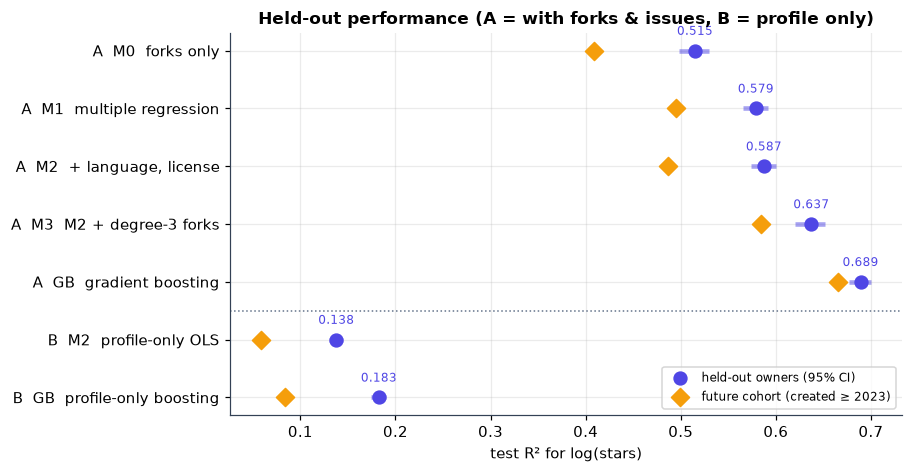

In [11]:
order = list(SPECS)[::-1]
a = final_table.set_index('model').loc[order]; t = time_table.set_index('model').loc[order]
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.hlines(y, a.R2_lo, a.R2_hi, color=INDIGO, lw=3, alpha=.5)
ax.scatter(a.R2, y, s=70, color=INDIGO, zorder=3, label='held-out owners (95% CI)')
ax.scatter(t.R2, y, s=70, marker='D', color=AMBER, zorder=3, label='future cohort (created ≥ 2023)')
for yi, r in zip(y, a.R2): ax.text(r, yi + .27, f'{r:.3f}', ha='center', fontsize=8, color=INDIGO)
ax.set_yticks(y); ax.set_yticklabels(order); ax.axhline(1.5, color=SLATE, lw=1, ls=':')
ax.set(xlabel='test R² for log(stars)', title='Held-out performance (A = with forks & issues, B = profile only)')
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout(); save(fig, '03_model_comparison.png')

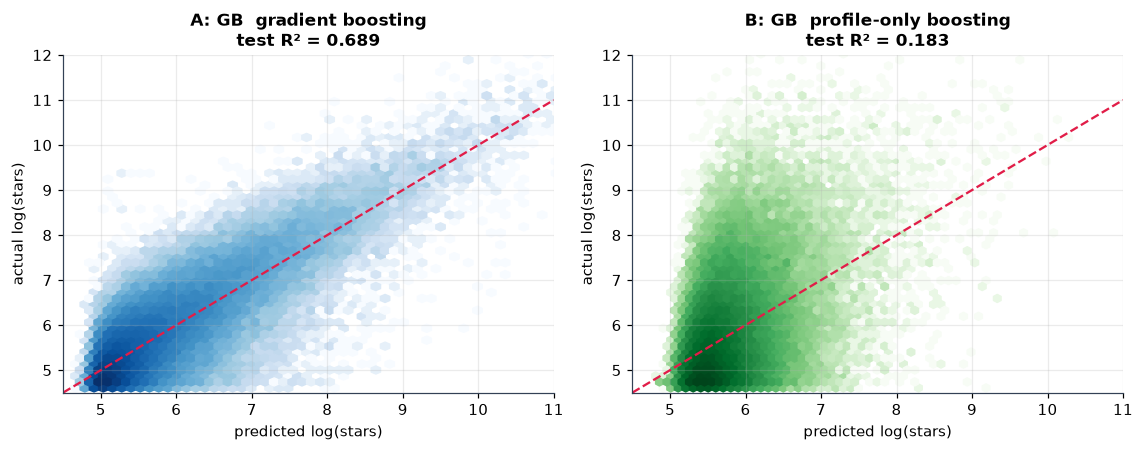

In [12]:
best = 'A  GB  gradient boosting'
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
for a_, name, cm in zip(ax, [best, 'B  GB  profile-only boosting'], ['Blues', 'Greens']):
    a_.hexbin(test_pred[name], test.log_stars, gridsize=55, bins='log', cmap=cm, mincnt=1)
    lim = [4.5, 11]; a_.plot(lim, lim, color=ROSE, lw=1.5, ls='--')
    a_.set(xlim=lim, ylim=(4.5, 12), xlabel='predicted log(stars)', ylabel='actual log(stars)',
           title=f"{name[:1]}: {name[3:]}\ntest R² = {final_table.set_index('model').loc[name, 'R2']:.3f}")
fig.tight_layout(); save(fig, '04_pred_vs_actual.png')

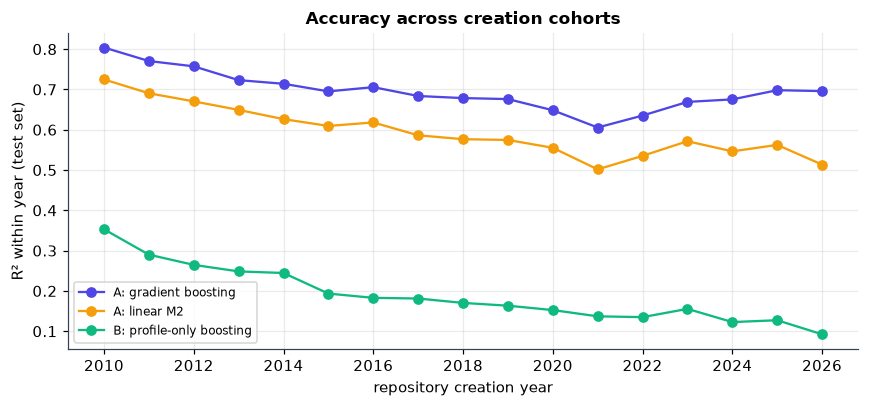

In [13]:
names = (best, 'A  M2  + language, license', 'B  GB  profile-only boosting')
MIN_N = 500 if len(test) > 50_000 else 50      # skip tiny cohorts (smaller threshold for the bundled sample)
yr = test.assign(**{n: test_pred[n] for n in names})
by_year = pd.DataFrame([{'year': yv, 'n': len(g), **{n: r2_score(g.log_stars, g[n]) for n in names}}
                        for yv, g in yr.groupby('created_year') if len(g) >= MIN_N])
results['r2_by_created_year'] = by_year.round(4).to_dict('records')
fig, ax = plt.subplots(figsize=(8, 3.8))
for n, c, lab in [(best, INDIGO, 'A: gradient boosting'), ('A  M2  + language, license', AMBER, 'A: linear M2'),
                  ('B  GB  profile-only boosting', EMERALD, 'B: profile-only boosting')]:
    ax.plot(by_year.year, by_year[n], 'o-', color=c, label=lab)
ax.set(xlabel='repository creation year', ylabel='R² within year (test set)', title='Accuracy across creation cohorts'); ax.legend(fontsize=8)
fig.tight_layout(); save(fig, '05_r2_by_year.png')

## 7. Interpretation: what is associated with stars?

Coefficients come from the linear model M2 refit on train + validation, with **owner-clustered** standard errors (repositories of one owner are not independent; `cov_type='cluster'`, groups = owner). HC3 is kept only as a comparison in section 8. Reading: *holding the other features fixed, a repository that differs by this amount has this multiplicative (percent) difference in fitted stars*. M2 is fitted on log(stars), so exponentiated coefficients are multiplicative differences in fitted, conditional geometric-mean stars, not differences in arithmetic expected star counts (no retransformation is applied). Forks, open issues, size and description length enter as `log1p`, so their contrasts are for a 10% increase in `1 + feature`, not in the feature itself (the two differ for small counts). These are descriptive associations. Because forks and issues are consequences of attention, coefficients on the other features are partly "adjusted for popularity" and should not be read as effects.

In [14]:
dv = final['A  M2  + language, license'].prep.transform(dev)
m2 = final['A  M2  + language, license'].result
hc3 = smf.ols(formula(1), dv).fit(cov_type='HC3')          # row-level robust SEs, comparison only
owner_codes = pd.factorize(dv.owner)[0]
rob = smf.ols(formula(1), dv).fit(cov_type='cluster', cov_kwds={'groups': owner_codes})
results['effects_se_method'] = {'method': 'owner-clustered (CR1, statsmodels cov_type=cluster)', 'n_owner_clusters': int(owner_codes.max() + 1)}
ci = rob.conf_int(); lo_, hi_ = ci[0], ci[1]

per10 = {'lf': 'forks: 1 + forks +10%', 'log_issues': 'open issues: 1 + issues +10%', 'log_size': 'size: 1 + size_kb +10%', 'log_desc_len': 'description length: 1 + length +10%'}
per_unit = {'age_years': 'age +1 year', 'years_since_push': 'last push +1 year older', 'n_topics': '+1 topic', 'name_len': '+1 name character'}
flag_lab = {'owner_type_Organization': 'owned by an organization', 'has_discussions': 'Discussions enabled',
            'has_homepage': 'has homepage', 'archived': 'archived', 'has_wiki': 'wiki enabled', 'has_pages': 'GitHub Pages',
            'has_projects': 'Projects enabled', 'has_issues': 'Issues enabled', 'is_template': 'template repository',
            'default_branch_main': 'default branch main/master'}
eff = []
for k, lab in per10.items():
    eff.append((lab, *[(1.1 ** v - 1) * 100 for v in (rob.params[k], lo_[k], hi_[k])]))
for k, lab in {**per_unit, **flag_lab}.items():
    eff.append((lab, *[(np.exp(v) - 1) * 100 for v in (rob.params[k], lo_[k], hi_[k])]))
eff = pd.DataFrame(eff, columns=['feature', 'pct', 'lo', 'hi']).sort_values('pct')
results['effects_description'] = 'multiplicative difference in fitted (conditional geometric-mean) stars, %, of the log(stars) OLS model M2; log1p features (size, forks, issues, description length): (1.1**coef-1)*100 for a 10% increase in 1 + feature; unit and indicator terms: (exp(coef)-1)*100'
results['effects_pct_stars'] = eff.round(2).to_dict('records')
print(eff.round(2).to_string(index=False))

                            feature    pct     lo     hi
                template repository -25.64 -28.10 -23.09
           owned by an organization -11.35 -12.73  -9.95
                       wiki enabled  -8.14  -9.58  -6.67
                   Projects enabled  -6.84  -8.90  -4.74
                        age +1 year  -1.88  -2.03  -1.73
                           archived  -1.39  -3.15   0.40
                  +1 name character  -1.28  -1.36  -1.21
            last push +1 year older  -1.26  -1.45  -1.07
             size: 1 + size_kb +10%  -0.05  -0.06  -0.03
description length: 1 + length +10%   0.33   0.30   0.37
       open issues: 1 + issues +10%   0.76   0.73   0.80
                           +1 topic   1.12   1.04   1.21
                       has homepage   1.60   0.63   2.59
                     Issues enabled   3.18  -1.84   8.45
                       GitHub Pages   4.55   3.23   5.88
              forks: 1 + forks +10%   5.63   5.56   5.71
         default branch main/ma

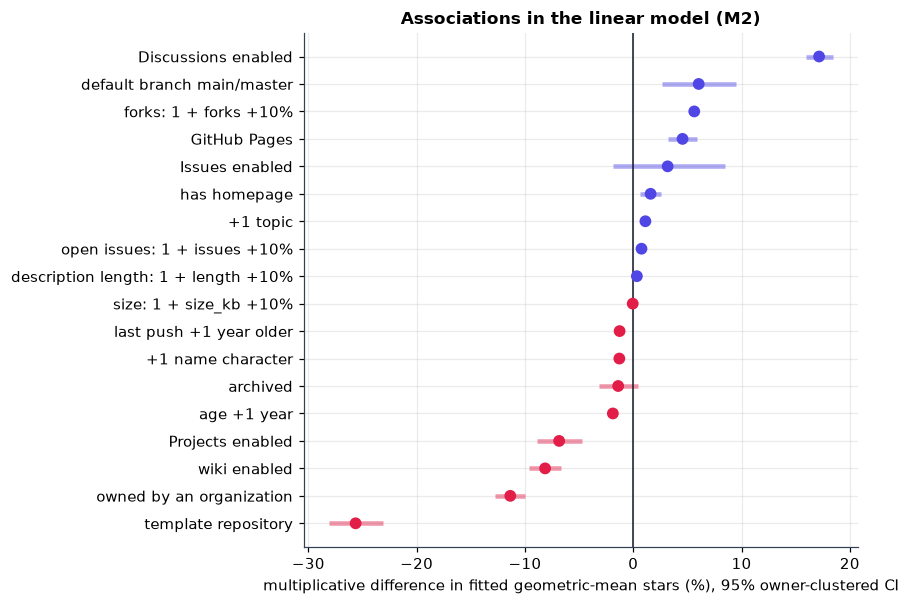

In [15]:
e = eff.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 5.6))
colors = [ROSE if v < 0 else INDIGO for v in e.pct]
ax.hlines(e.index, e.lo, e.hi, color=colors, lw=3, alpha=.45)
ax.scatter(e.pct, e.index, color=colors, s=45, zorder=3)
ax.axvline(0, color='#0f172a', lw=1)
ax.set_yticks(e.index); ax.set_yticklabels(e.feature)
ax.set(xlabel='multiplicative difference in fitted geometric-mean stars (%), 95% owner-clustered CI', title='Associations in the linear model (M2)')
fig.tight_layout(); save(fig, '06_associations.png')

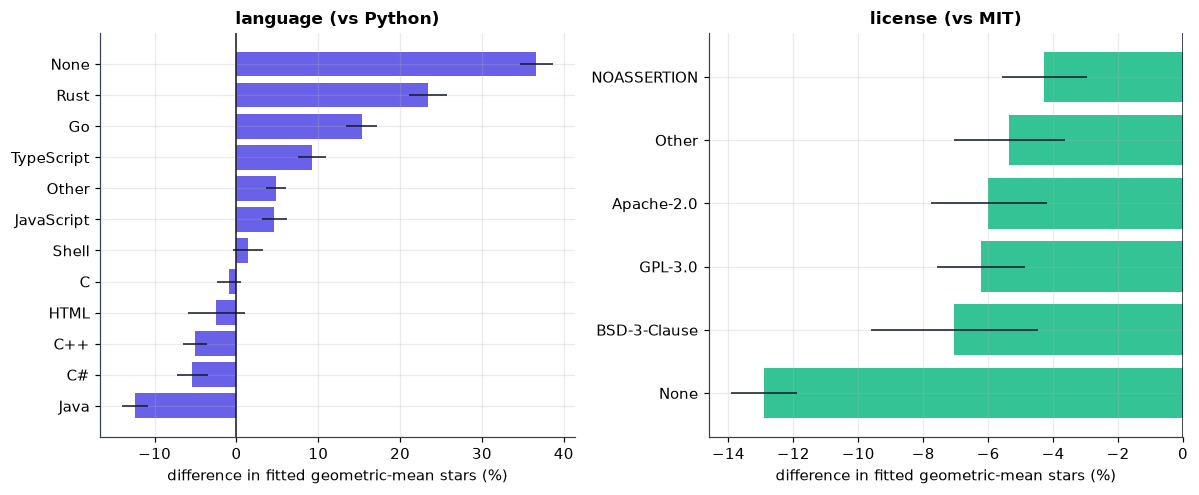

               group        label  coef_pct
language (vs Python)         Java     -12.5
language (vs Python)           C#      -5.4
language (vs Python)          C++      -5.1
language (vs Python)         HTML      -2.5
language (vs Python)            C      -0.9
language (vs Python)        Shell       1.4
language (vs Python)   JavaScript       4.6
language (vs Python)        Other       4.9
language (vs Python)   TypeScript       9.2
language (vs Python)           Go      15.3
language (vs Python)         Rust      23.4
language (vs Python)         None      36.7
    license (vs MIT)         None     -12.9
    license (vs MIT) BSD-3-Clause      -7.1
    license (vs MIT)      GPL-3.0      -6.2
    license (vs MIT)   Apache-2.0      -6.0
    license (vs MIT)        Other      -5.4
    license (vs MIT)  NOASSERTION      -4.3


In [16]:
c = pd.DataFrame({'coef': rob.params, 'lo': lo_, 'hi': hi_})
c = c[c.index.str.startswith('C(')].copy()
c['label'] = c.index.str.extract(r'\[T\.(.*)\]', expand=False)
c['group'] = np.where(c.index.str.contains('lang_g'), 'language (vs Python)', 'license (vs MIT)')
for col in ('coef', 'lo', 'hi'): c[col + '_pct'] = (np.exp(c[col]) - 1) * 100
results['categorical_effects_pct'] = c[['group', 'label', 'coef_pct', 'lo_pct', 'hi_pct']].round(2).to_dict('records')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a_, (gname, g), col in zip(ax, c.groupby('group'), (INDIGO, EMERALD)):
    g = g.sort_values('coef_pct').reset_index(drop=True)
    a_.barh(g.index, g.coef_pct, color=col, alpha=.85)
    a_.errorbar(g.coef_pct, g.index, xerr=[g.coef_pct - g.lo_pct, g.hi_pct - g.coef_pct], fmt='none', ecolor='#0f172a', lw=1)
    a_.set_yticks(g.index); a_.set_yticklabels(g.label); a_.axvline(0, color='#0f172a', lw=1)
    a_.set(xlabel='difference in fitted geometric-mean stars (%)', title=gname)
fig.tight_layout(); save(fig, '07_language_license.png')
print(c[['group', 'label', 'coef_pct']].sort_values(['group', 'coef_pct']).round(1).to_string(index=False))

## 8. Diagnostics of the linear model

Residual checks on M2 (train + validation fit). Heteroscedasticity is significant but HC3 standard errors barely differ from the classical ones; owner-clustered standard errors are the ones used for the published intervals, and the table below shows how much they widen. With ~0.4 M rows nearly any test rejects, so the practical question is effect size, not p-values.

In [17]:
fitted, resid = m2.fittedvalues, m2.resid
X = m2.model.exog
Q, _ = np.linalg.qr(X); h = (Q ** 2).sum(1)
p_ = X.shape[1]; s2 = m2.mse_resid
cook = resid.values ** 2 / (p_ * s2) * h / (1 - h) ** 2
bp = het_breuschpagan(resid, X)
cmp_se = pd.DataFrame({'classic': m2.bse, 'HC3': hc3.bse, 'clustered': rob.bse}); ratio = cmp_se.HC3 / cmp_se.classic
ratio_cl = cmp_se.clustered / cmp_se.classic
diag = {'max_cooks_d': cook.max(), 'share_cooks_gt_4n': float((cook > 4 / len(cook)).mean()), 'max_leverage': h.max(),
        'resid_skew': stats.skew(resid), 'resid_excess_kurtosis': stats.kurtosis(resid),
        'durbin_watson_by_repo_id': durbin_watson(resid.loc[dv.sort_values('repo_id').index]),
        'breusch_pagan_LM': bp[0], 'share_fitted_below_log100': float((fitted < np.log(100)).mean()),
        'se_ratio_HC3_to_classic_median': ratio.median(), 'se_ratio_max': ratio.max(),
        'se_ratio_clustered_to_classic_median': ratio_cl.median(), 'se_ratio_clustered_to_classic_max': ratio_cl.max(),
        'se_ratio_clustered_to_classic_forks': ratio_cl['lf']}
samp = dv.sample(min(50000, len(dv)), random_state=1)
Xv = sm.add_constant(samp[NUM].astype(float))
diag['vif'] = {c_: variance_inflation_factor(Xv.values, i) for i, c_ in enumerate(NUM, start=1)}
results['diagnostics'] = diag
print({k: (round(v, 3) if not isinstance(v, dict) else {a: round(b, 2) for a, b in v.items()}) for k, v in diag.items()})

{'max_cooks_d': np.float64(0.001), 'share_cooks_gt_4n': 0.059, 'max_leverage': np.float64(0.001), 'resid_skew': np.float64(0.31), 'resid_excess_kurtosis': np.float64(1.147), 'durbin_watson_by_repo_id': np.float64(1.943), 'breusch_pagan_LM': np.float64(30068.185), 'share_fitted_below_log100': 0.049, 'se_ratio_HC3_to_classic_median': np.float64(1.023), 'se_ratio_max': np.float64(1.434), 'se_ratio_clustered_to_classic_median': np.float64(1.877), 'se_ratio_clustered_to_classic_max': np.float64(3.994), 'se_ratio_clustered_to_classic_forks': np.float64(3.907), 'vif': {'log_forks': np.float64(1.38), 'log_issues': np.float64(1.38), 'log_size': np.float64(1.15), 'age_years': np.float64(1.6), 'years_since_push': np.float64(1.56), 'n_topics': np.float64(1.19), 'log_desc_len': np.float64(1.09), 'name_len': np.float64(1.05)}}


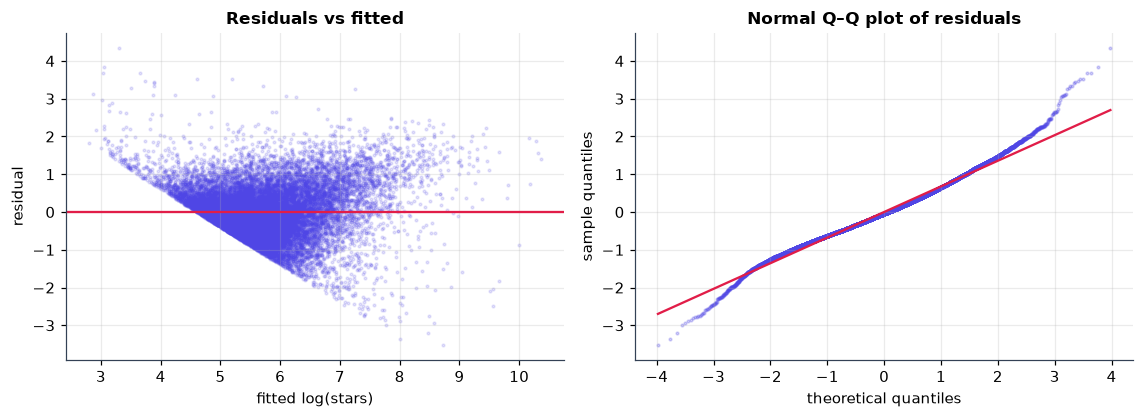

In [18]:
idx = np.random.default_rng(0).choice(len(resid), min(20000, len(resid)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax[0].scatter(fitted.iloc[idx], resid.iloc[idx], s=3, alpha=.15, color=INDIGO)
ax[0].axhline(0, color=ROSE, lw=1.5); ax[0].set(xlabel='fitted log(stars)', ylabel='residual', title='Residuals vs fitted')
(osm, osr), (slope, icpt, r) = stats.probplot(resid.iloc[idx], dist='norm')
ax[1].scatter(osm, osr, s=3, alpha=.25, color=INDIGO); ax[1].plot(osm, slope * osm + icpt, color=ROSE, lw=1.5)
ax[1].set(xlabel='theoretical quantiles', ylabel='sample quantiles', title='Normal Q–Q plot of residuals')
fig.tight_layout(); save(fig, '08_diagnostics.png')

## 9. Modelling decisions that did not help

Evaluated on the **validation** set (models fit on train), so the test set stays untouched.

In [19]:
prep_tr = FeaturePrep().fit(train); tr, va = prep_tr.transform(train), prep_tr.transform(val)
out = {}
# (a) raw stars as the response
m_raw = smf.ols(formula(1).replace('log_stars', 'stars'), tr).fit(); p_raw = m_raw.predict(va)
out['raw_stars_R2_val'] = r2_score(va.stars, p_raw); out['raw_stars_negative_predictions'] = float((p_raw < 0).mean())
# (b) redundant derived features built from forks, age and last push
m2_tr = smf.ols(formula(1), tr).fit()
m_b = smf.ols(formula(1) + ' + log_forks_per_year + days_active', tr).fit()
out['derived_R2_val'] = r2_score(va.log_stars, m_b.predict(va)); out['m2_R2_val'] = r2_score(va.log_stars, m2_tr.predict(va))
out['derived_forks_coef'] = m_b.params['lf']; out['m2_forks_coef'] = m2_tr.params['lf']
out['derived_forks_se'] = m_b.bse['lf']; out['m2_forks_se'] = m2_tr.bse['lf']
Xd = sm.add_constant(tr.sample(min(50000, len(tr)), random_state=1)[NUM + ['log_forks_per_year', 'days_active']].astype(float))
out['vif_with_derived'] = {c_: variance_inflation_factor(Xd.values, i) for i, c_ in enumerate(NUM + ['log_forks_per_year', 'days_active'], start=1)}
results['rejected_attempts_validation'] = out
print('(a) raw stars: validation R2 %.3f, negative predictions %.1f%%' % (out['raw_stars_R2_val'], 100 * out['raw_stars_negative_predictions']))
print('(b) + derived features: val R2 %.3f vs M2 %.3f | forks coefficient %.3f -> %.3f, SE %.4f -> %.4f' % (
    out['derived_R2_val'], out['m2_R2_val'], out['m2_forks_coef'], out['derived_forks_coef'], out['m2_forks_se'], out['derived_forks_se']))
print('    VIF with derived features:', {k: round(v, 1) for k, v in out['vif_with_derived'].items()})

(a) raw stars: validation R2 0.144, negative predictions 31.0%
(b) + derived features: val R2 0.607 vs M2 0.603 | forks coefficient 0.570 -> 0.398, SE 0.0012 -> 0.0030
    VIF with derived features: {'log_forks': np.float64(8.7), 'log_issues': np.float64(1.4), 'log_size': np.float64(1.2), 'age_years': np.float64(86455.7), 'years_since_push': np.float64(51193.4), 'n_topics': np.float64(1.2), 'log_desc_len': np.float64(1.1), 'name_len': np.float64(1.1), 'log_forks_per_year': np.float64(8.6), 'days_active': np.float64(71277.2)}


## 10. Summary and limitations

**Results are written to `results/metrics.json` and `results/model_comparison.csv`; the README quotes those files.**

Limitations
- **Selected sample.** Only repositories with ≥100 stars are included, so low-popularity repositories are absent and the outcome is truncated at `log(100)`; coefficients describe association *within* that population.
- **Same-snapshot predictors.** Forks and open issues are measured together with stars. Task A is association, not forecasting; Task B is the less leaky comparison, yet features such as `years_since_push` and description length are still observed after the fact, so it is not a prediction at repository creation either.
- **Observational data.** No causal interpretation of any coefficient (e.g. Discussions, license, language).
- **Collection.** GitHub search is a point-in-time snapshot (2026-10-10); see `docs/data.md` and `docs/data_audit.json` for coverage checks (the cache holds one repository fewer than the totals GitHub reported).
- **Dependence.** Splits are grouped by owner, but repositories can still be related through organisations, forks, or topics.

In [20]:
pd.concat([final_table.assign(split='random owner-grouped test'),
           time_table.assign(split='time holdout (created >= 2023)')]).round(4).to_csv(RES / 'model_comparison.csv', index=False)
default = lambda o: o.item() if hasattr(o, 'item') else str(o)
(RES / 'metrics.json').write_text(json.dumps(results, indent=2, default=default))
print('saved results/metrics.json and results/model_comparison.csv')

saved results/metrics.json and results/model_comparison.csv
